# FOCUSED EXPERIMENTS: Regression + CAMCSA

Based on best results from previous experiments.

**Base**: ConcatFusion (best fusion: 0.8832 QWK)

## Experiments (4 total)

| Variant | Description |
|---------|-------------|
| B0_ConcatFusion_Baseline | Current Best (0.8832) |
| R1_Regression_MSE | Regression + MSE Loss + Threshold Optimization |
| R2_Regression_SmoothL1 | Regression + Smooth L1 Loss |
| CAMCSA_Full | CAM + Cross-Slide Augmentation |

## Time Estimate
4 variants x 5 folds = 20 training runs (~10-15 hours)

## IMPORTS AND SETUP

In [1]:
import os
import json
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    cohen_kappa_score,
    accuracy_score,
    f1_score,
    confusion_matrix,
    precision_score,
    recall_score,
)
from scipy import stats
from scipy.optimize import minimize
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
import random

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## CONFIGURATION

In [2]:
CONFIG = {
    # Paths
    'features_dir': '/content/drive/MyDrive/CLAM_TR_Features/uni/',
    'checkpoints_dir': '/content/drive/MyDrive/CLAM_TR_Checkpoints/',
    'results_dir': '/content/drive/MyDrive/CLAM_TR_Results/v14_Regression_CAMCSA/',

    # Model
    'feature_dim': 1024,
    'hidden_dim': 512,
    'n_classes': 6,
    'num_heads': 8,
    'K': 128,

    # PROVEN BEST HP (from ablation)
    'best_hp': {
        'dropout': 0.15,
        'attention_temperature': 0.7,
        'lr': 1e-4,
        'weight_decay': 1e-5,
        'focal_gamma': 1.0,
        'gamma_values': [0.88, 0.90, 0.92, 0.94, 0.96, 0.98, 0.99, 0.995],
    },

    # Training
    'epochs': 50,
    'early_stopping_patience': 10,
    'n_folds': 5,
    'seed': 42,
}

random.seed(CONFIG['seed'])
np.random.seed(CONFIG['seed'])
torch.manual_seed(CONFIG['seed'])
torch.cuda.manual_seed_all(CONFIG['seed'])

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

os.makedirs(CONFIG['results_dir'], exist_ok=True)
print(f'Results will be saved to: {CONFIG["results_dir"]}')

Device: cuda
Results will be saved to: /content/drive/MyDrive/CLAM_TR_Results/v14_Regression_CAMCSA/


## CHECKPOINT MANAGER

In [3]:
class CheckpointManager:
    """Manages checkpoints for resumable training."""

    def __init__(self, checkpoint_dir):
        self.checkpoint_dir = checkpoint_dir
        os.makedirs(checkpoint_dir, exist_ok=True)
        self.progress_file = os.path.join(checkpoint_dir, 'experiment_progress.json')
        self.fold_progress_file = os.path.join(checkpoint_dir, 'fold_progress.json')

    def _save_json(self, filepath, data):
        for attempt in range(3):
            try:
                with open(filepath, 'w') as f:
                    json.dump(data, f, indent=2, default=str)
                return True
            except Exception as e:
                print(f'Save attempt {attempt+1} failed: {e}')
                time.sleep(1)
        return False

    def _load_json(self, filepath):
        if os.path.exists(filepath):
            try:
                with open(filepath, 'r') as f:
                    return json.load(f)
            except:
                return {}
        return {}

    def get_completed_experiments(self):
        return self._load_json(self.progress_file)

    def is_experiment_completed(self, experiment_name):
        return experiment_name in self.get_completed_experiments()

    def save_experiment_result(self, experiment_name, results):
        data = self._load_json(self.progress_file)
        data[experiment_name] = {
            'results': results,
            'completed_at': datetime.now().isoformat()
        }
        self._save_json(self.progress_file, data)
        print(f'  [Checkpoint] Saved {experiment_name}')

    def load_experiment_result(self, experiment_name):
        data = self.get_completed_experiments()
        if experiment_name in data:
            return data[experiment_name]['results']
        return None

    def get_fold_progress(self, experiment_name):
        data = self._load_json(self.fold_progress_file)
        return data.get(experiment_name, {'completed_folds': [], 'fold_results': []})

    def save_fold_result(self, experiment_name, fold_idx, fold_metrics):
        data = self._load_json(self.fold_progress_file)
        if experiment_name not in data:
            data[experiment_name] = {
                'completed_folds': [],
                'fold_results': [],
                'started_at': datetime.now().isoformat()
            }
        if fold_idx not in data[experiment_name]['completed_folds']:
            data[experiment_name]['completed_folds'].append(fold_idx)
            data[experiment_name]['fold_results'].append({
                'fold': fold_idx,
                'metrics': fold_metrics,
                'completed_at': datetime.now().isoformat()
            })
        data[experiment_name]['last_updated'] = datetime.now().isoformat()
        self._save_json(self.fold_progress_file, data)

    def clear_fold_progress(self, experiment_name):
        data = self._load_json(self.fold_progress_file)
        if experiment_name in data:
            del data[experiment_name]
            self._save_json(self.fold_progress_file, data)

    def get_status(self):
        experiments = self.get_completed_experiments()
        fold_data = self._load_json(self.fold_progress_file)
        return {
            'completed_experiments': len(experiments),
            'in_progress_experiments': len(fold_data),
            'experiment_names': list(experiments.keys()),
            'in_progress_names': list(fold_data.keys())
        }

checkpoint_manager = CheckpointManager(CONFIG['results_dir'])
status = checkpoint_manager.get_status()
print(f'\n[Checkpoint Status]')
print(f'  Completed experiments: {status["completed_experiments"]}')
print(f'  In-progress experiments: {status["in_progress_experiments"]}')


[Checkpoint Status]
  Completed experiments: 3
  In-progress experiments: 0


## METRICS COMPUTATION

In [4]:
def compute_all_metrics(y_true, y_pred):
    """Compute ALL metrics."""
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    qwk = cohen_kappa_score(y_true, y_pred, weights='quadratic')

    y_true_binary = (y_true > 0).astype(int)
    y_pred_binary = (y_pred > 0).astype(int)
    binary_accuracy = accuracy_score(y_true_binary, y_pred_binary)
    binary_precision = precision_score(y_true_binary, y_pred_binary, zero_division=0)
    binary_recall = recall_score(y_true_binary, y_pred_binary, zero_division=0)
    binary_f1 = f1_score(y_true_binary, y_pred_binary, zero_division=0)
    tn = ((y_true_binary == 0) & (y_pred_binary == 0)).sum()
    fp = ((y_true_binary == 0) & (y_pred_binary == 1)).sum()
    binary_specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    grading_accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

    per_grade_accuracy = {}
    per_grade_support = {}
    for g in range(6):
        mask = (y_true == g)
        per_grade_support[g] = int(mask.sum())
        per_grade_accuracy[g] = float((y_pred[mask] == g).mean()) if mask.sum() > 0 else 0.0

    cm = confusion_matrix(y_true, y_pred, labels=range(6))

    return {
        'qwk': float(qwk),
        'binary_accuracy': float(binary_accuracy),
        'binary_precision': float(binary_precision),
        'binary_recall': float(binary_recall),
        'binary_specificity': float(binary_specificity),
        'binary_f1': float(binary_f1),
        'grading_accuracy': float(grading_accuracy),
        'macro_f1': float(macro_f1),
        'per_grade_accuracy': per_grade_accuracy,
        'per_grade_support': per_grade_support,
        'confusion_matrix': cm.tolist(),
    }

## THRESHOLD OPTIMIZATION (For Regression)

In [5]:
def optimize_thresholds(predictions, labels, n_classes=6):
    """Find optimal thresholds to maximize QWK."""
    predictions = np.array(predictions)
    labels = np.array(labels)

    def neg_qwk(thresholds):
        t = np.sort(thresholds)
        pred_classes = np.digitize(predictions, t)
        pred_classes = np.clip(pred_classes, 0, n_classes - 1)
        return -cohen_kappa_score(labels, pred_classes, weights='quadratic')

    init_thresholds = [0.5, 1.5, 2.5, 3.5, 4.5]
    result = minimize(neg_qwk, init_thresholds, method='Nelder-Mead', options={'maxiter': 1000})

    return np.sort(result.x)


def apply_thresholds(predictions, thresholds):
    """Apply thresholds to convert continuous predictions to classes."""
    predictions = np.array(predictions)
    thresholds = np.sort(thresholds)
    pred_classes = np.digitize(predictions, thresholds)
    return np.clip(pred_classes, 0, 5)

## LOSS FUNCTIONS

In [6]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=1.0):
        super().__init__()
        self.gamma = gamma

    def forward(self, logits, target):
        if logits.dim() == 1:
            logits = logits.unsqueeze(0)
        if isinstance(target, (int, float)):
            target = torch.tensor([int(target)], device=logits.device)
        elif target.dim() == 0:
            target = target.unsqueeze(0)
        ce = F.cross_entropy(logits, target.long(), reduction='none')
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()


class RegressionMSELoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.mse = nn.MSELoss()

    def forward(self, pred, target):
        if pred.dim() == 2:
            pred = pred.squeeze(-1)
        if pred.dim() == 0:
            pred = pred.unsqueeze(0)
        target = torch.tensor([float(target)], device=pred.device) if isinstance(target, (int, float)) else target.float()
        if target.dim() == 0:
            target = target.unsqueeze(0)
        return self.mse(pred, target)


class RegressionSmoothL1Loss(nn.Module):
    def __init__(self):
        super().__init__()
        self.smooth_l1 = nn.SmoothL1Loss()

    def forward(self, pred, target):
        if pred.dim() == 2:
            pred = pred.squeeze(-1)
        if pred.dim() == 0:
            pred = pred.unsqueeze(0)
        target = torch.tensor([float(target)], device=pred.device) if isinstance(target, (int, float)) else target.float()
        if target.dim() == 0:
            target = target.unsqueeze(0)
        return self.smooth_l1(pred, target)


class SoftFocalLoss(nn.Module):
    """Focal loss with soft label support (for CSA)."""
    def __init__(self, n_classes=6, gamma=1.0):
        super().__init__()
        self.n_classes = n_classes
        self.gamma = gamma

    def forward(self, logits, soft_label):
        if logits.dim() == 1:
            logits = logits.unsqueeze(0)

        soft_target = self._create_soft_target(soft_label, logits.device)
        probs = F.softmax(logits, dim=1)
        log_probs = F.log_softmax(logits, dim=1)
        focal_weight = (1 - (probs * soft_target).sum(dim=1)) ** self.gamma
        loss = -focal_weight * (soft_target * log_probs).sum(dim=1)
        return loss.mean()

    def _create_soft_target(self, soft_label, device):
        target = torch.zeros(1, self.n_classes, device=device)
        soft_label = float(soft_label)
        soft_label = max(0, min(soft_label, self.n_classes - 1))
        lower = int(soft_label)
        upper = min(lower + 1, self.n_classes - 1)
        weight_upper = soft_label - lower
        target[0, lower] = 1 - weight_upper
        if lower != upper:
            target[0, upper] = weight_upper
        return target

## CAM (CLASS ACTIVATION MAP) MODULE

In [7]:
class CAMModule(nn.Module):
    """
    Class Activation Map - shows WHY model predicts each class.
    Better than attention for patch importance.
    """
    def __init__(self, hidden_dim, n_classes):
        super().__init__()
        self.n_classes = n_classes
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, h):
        cam_scores = self.classifier(h)
        cam_weights = F.softmax(cam_scores, dim=0)
        return cam_scores, cam_weights

    def get_patch_importance(self, h, target_class=None):
        """Get patch importance for CSA selection."""
        cam_scores, _ = self.forward(h)
        if target_class is None:
            return cam_scores.max(dim=1)[0]
        return cam_scores[:, target_class]

## CROSS-SLIDE AUGMENTATION (CSA)

In [8]:
class CrossSlideAugmentation:
    """Mix patches from different slides."""
    def __init__(self, mix_ratio=0.5, use_soft_labels=True):
        self.mix_ratio = mix_ratio
        self.use_soft_labels = use_soft_labels

    def augment(self, feat_a, label_a, feat_b, label_b, importance_a=None, importance_b=None):
        N_a = feat_a.shape[0]
        N_b = feat_b.shape[0]

        n_from_a = max(10, min(int(N_a * self.mix_ratio), N_a))
        n_from_b = max(10, min(int(N_b * (1 - self.mix_ratio)), N_b))

        if importance_a is not None and len(importance_a) >= n_from_a:
            idx_a = torch.topk(importance_a, n_from_a).indices
        else:
            idx_a = torch.randperm(N_a)[:n_from_a]

        if importance_b is not None and len(importance_b) >= n_from_b:
            idx_b = torch.topk(importance_b, n_from_b).indices
        else:
            idx_b = torch.randperm(N_b)[:n_from_b]

        mixed_feat = torch.cat([feat_a[idx_a], feat_b[idx_b]], dim=0)

        if self.use_soft_labels:
            weight_a = len(idx_a) / (len(idx_a) + len(idx_b))
            mixed_label = weight_a * label_a + (1 - weight_a) * label_b
        else:
            mixed_label = label_a if self.mix_ratio >= 0.5 else label_b

        return mixed_feat, mixed_label

## MODEL COMPONENTS

In [9]:
class GatedAttention(nn.Module):
    def __init__(self, input_dim=512, hidden_dim=256, dropout=0.25):
        super().__init__()
        self.attention_a = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.Tanh(), nn.Dropout(dropout)
        )
        self.attention_b = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.Sigmoid(), nn.Dropout(dropout)
        )
        self.attention_c = nn.Linear(hidden_dim, 1)

    def forward(self, x, temperature=1.0):
        a = self.attention_a(x)
        b = self.attention_b(x)
        return self.attention_c(a * b).squeeze(-1) / temperature


class SwishGate(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        return x * torch.sigmoid(self.proj(x))


class FFNBlock(nn.Module):
    def __init__(self, dim, expansion=4, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, dim * expansion), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(dim * expansion, dim), nn.Dropout(dropout),
        )
        self.norm = nn.LayerNorm(dim)

    def forward(self, x):
        return x + self.net(self.norm(x))


class RetentionHead(nn.Module):
    def __init__(self, hidden_dim, num_heads, gamma=0.9):
        super().__init__()
        self.head_dim = hidden_dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.gamma = gamma
        self.W_Q = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_K = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_V = nn.Linear(hidden_dim, self.head_dim, bias=False)

    def forward(self, x):
        Q, K, V = self.W_Q(x), self.W_K(x), self.W_V(x)
        scores = torch.matmul(Q, K.transpose(-2, -1)) * self.scale
        attn = F.softmax(scores, dim=-1)
        return torch.matmul(attn, V)


class RetentionModule(nn.Module):
    def __init__(self, hidden_dim=512, num_heads=8):
        super().__init__()
        gamma_values = CONFIG['best_hp']['gamma_values']
        self.heads = nn.ModuleList([
            RetentionHead(hidden_dim, num_heads, gamma_values[i]) for i in range(num_heads)
        ])
        self.output_proj = nn.Linear(hidden_dim, hidden_dim)

    def forward(self, x):
        head_outputs = [head(x) for head in self.heads]
        return self.output_proj(torch.cat(head_outputs, dim=-1))


class RetNetEnhancement(nn.Module):
    """FIXED for GroupNorm dimension issues."""
    def __init__(self, hidden_dim):
        super().__init__()
        self.norm = nn.GroupNorm(8, hidden_dim)
        self.gate = SwishGate(hidden_dim)
        self.ffn = FFNBlock(hidden_dim, 4)
        self.dropout = nn.Dropout(0.1)

    def forward(self, x, identity=None):
        out = self.dropout(x)
        # FIX: GroupNorm needs (N, C, *) - add dimensions if needed
        if out.dim() == 1:
            out = self.norm(out.unsqueeze(0).unsqueeze(-1)).squeeze(-1).squeeze(0)
        else:
            out = self.norm(out.unsqueeze(-1)).squeeze(-1)
        if identity is not None:
            out = out + identity
        out = self.gate(out)
        out = self.ffn(out)
        return out


class ConcatFusion(nn.Module):
    """Best fusion from experiments!"""
    def __init__(self, hidden_dim):
        super().__init__()
        self.proj = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1)
        )

    def forward(self, M_clam, M_retention):
        return self.proj(torch.cat([M_clam, M_retention], dim=-1))

## MAIN MODEL

In [10]:
class CLAMRetNetModel(nn.Module):
    """
    CLAM + RetNet with ConcatFusion (best fusion).
    Supports: Classification, Regression, CAM, CSA
    """
    def __init__(self, input_dim=1024, hidden_dim=512, n_classes=6, num_heads=8, config=None):
        super().__init__()

        if config is None:
            config = {}

        self.output_type = config.get('output_type', 'classification')
        self.use_cam = config.get('use_cam', False)
        dropout = CONFIG['best_hp']['dropout']

        # Feature transform
        self.feature_transform = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # CLAM attention
        self.attention = GatedAttention(hidden_dim, hidden_dim // 2, dropout)

        # CAM module (optional)
        if self.use_cam:
            self.cam = CAMModule(hidden_dim, n_classes)
        else:
            self.cam = None

        # Retention + Enhancement
        self.retention = RetentionModule(hidden_dim, num_heads)
        self.retnet_enhance = RetNetEnhancement(hidden_dim)

        # ConcatFusion (BEST!)
        self.fusion = ConcatFusion(hidden_dim)

        # Output head
        if self.output_type == 'regression':
            self.head = nn.Sequential(
                nn.Linear(hidden_dim, hidden_dim // 2),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(hidden_dim // 2, 1)
            )
        else:
            self.head = nn.Sequential(
                nn.Linear(hidden_dim, hidden_dim // 2),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(hidden_dim // 2, n_classes)
            )

    def forward(self, x, coords=None, return_importance=False):
        temperature = CONFIG['best_hp']['attention_temperature']

        h = self.feature_transform(x)

        # Attention scores
        A = self.attention(h, temperature)
        A_softmax = F.softmax(A, dim=0)

        # CAM importance (if enabled)
        if self.use_cam:
            cam_importance = self.cam.get_patch_importance(h)
            combined_importance = A_softmax + F.softmax(cam_importance, dim=0)
        else:
            combined_importance = A_softmax
            cam_importance = None

        # Top-K selection
        K = min(CONFIG['K'], h.size(0))
        topk_indices = torch.topk(combined_importance, K).indices
        h_topk = h[topk_indices]
        A_topk = A_softmax[topk_indices]

        # CLAM aggregation
        M_clam = torch.sum(A_topk.unsqueeze(-1) * h_topk, dim=0)

        # Retention
        M_retention = torch.mean(self.retention(h_topk), dim=0)
        M_retention = self.retnet_enhance(M_retention, M_retention)

        # ConcatFusion
        M = self.fusion(M_clam, M_retention)

        # Output
        out = self.head(M)

        if self.output_type == 'regression':
            out = torch.clamp(out.squeeze(-1), 0, 5)

        if return_importance:
            return out, combined_importance
        return out

    def get_cam_importance(self, x):
        """Get CAM importance for CSA."""
        if self.cam is None:
            return None
        h = self.feature_transform(x)
        return self.cam.get_patch_importance(h)

## DATASET WITH CSA SUPPORT

In [11]:
class PANDADataset(Dataset):
    def __init__(self, slide_ids, labels, features_dir,
                 use_csa=False, csa_config=None, all_slides_data=None, model=None, device=None):
        self.slide_ids = slide_ids
        self.labels = labels
        self.features_dir = features_dir
        self.use_csa = use_csa
        self.all_slides_data = all_slides_data
        self.model = model  # For CAM-based importance
        self.device = device  # Device for CAM computation

        csa_config = csa_config or {}
        self.csa_augment_prob = csa_config.get('augment_prob', 0.3)
        self.csa = CrossSlideAugmentation(
            mix_ratio=csa_config.get('mix_ratio', 0.5),
            use_soft_labels=csa_config.get('use_soft_labels', True)
        ) if use_csa else None

    def __len__(self):
        return len(self.slide_ids)

    def __getitem__(self, idx):
        data = torch.load(
            os.path.join(self.features_dir, f'{self.slide_ids[idx]}.pt'),
            map_location='cpu'
        )
        feat = data['features']
        coord = data['coordinates']
        label = self.labels[idx]
        is_soft_label = False

        if self.use_csa and self.all_slides_data and random.random() < self.csa_augment_prob:
            mix_idx = random.randint(0, len(self.all_slides_data) - 1)
            mix_slide_id, mix_label = self.all_slides_data[mix_idx]

            mix_data = torch.load(
                os.path.join(self.features_dir, f'{mix_slide_id}.pt'),
                map_location='cpu'
            )

            # Get CAM importance if model available
            importance_a, importance_b = None, None
            if self.model is not None and self.device is not None:
                with torch.no_grad():
                    # Move features to model's device for CAM computation
                    feat_gpu = feat.to(self.device)
                    mix_feat_gpu = mix_data['features'].to(self.device)
                    importance_a = self.model.get_cam_importance(feat_gpu).cpu()
                    importance_b = self.model.get_cam_importance(mix_feat_gpu).cpu()

            feat, label = self.csa.augment(
                feat, label, mix_data['features'], mix_label,
                importance_a, importance_b
            )
            coord = None
            is_soft_label = True

        return feat, coord, label, self.slide_ids[idx], is_soft_label


def collate_fn(batch):
    return batch[0]

## MODEL VARIANTS

In [12]:
MODEL_VARIANTS = {
    # Baseline (current best)
    'B0_ConcatFusion_Baseline': {
        'description': 'ConcatFusion Baseline (Current Best: 0.8832)',
        'output_type': 'classification',
        'loss_type': 'focal',
        'use_cam': False,
        'use_csa': False,
    },

    # Regression experiments
    'R1_Regression_MSE': {
        'description': 'Regression + MSE Loss + Threshold Optimization',
        'output_type': 'regression',
        'loss_type': 'mse',
        'use_cam': False,
        'use_csa': False,
    },

    'R2_Regression_SmoothL1': {
        'description': 'Regression + Smooth L1 Loss + Threshold Optimization',
        'output_type': 'regression',
        'loss_type': 'smooth_l1',
        'use_cam': False,
        'use_csa': False,
    },

    # Full CAMCSA
    'CAMCSA_Full': {
        'description': 'Full CAMCSA (CAM + Cross-Slide Augmentation)',
        'output_type': 'classification',
        'loss_type': 'focal',
        'use_cam': True,
        'use_csa': True,
        'csa_config': {
            'mix_ratio': 0.5,
            'augment_prob': 0.3,
            'use_soft_labels': True,
        },
    },
}

print(f'\nTotal variants: {len(MODEL_VARIANTS)}')
for key, cfg in MODEL_VARIANTS.items():
    print(f'  {key}: {cfg["description"]}')


Total variants: 4
  B0_ConcatFusion_Baseline: ConcatFusion Baseline (Current Best: 0.8832)
  R1_Regression_MSE: Regression + MSE Loss + Threshold Optimization
  R2_Regression_SmoothL1: Regression + Smooth L1 Loss + Threshold Optimization
  CAMCSA_Full: Full CAMCSA (CAM + Cross-Slide Augmentation)


## TRAINING

In [13]:
class EarlyStopping:
    def __init__(self, patience=10):
        self.patience = patience
        self.counter = 0
        self.best = None

    def __call__(self, score):
        if self.best is None or score > self.best + 0.001:
            self.best = score
            self.counter = 0
        else:
            self.counter += 1
        return self.counter >= self.patience


def train_fold(config, train_df, val_df, device):
    """Train one fold."""

    is_regression = config.get('output_type') == 'regression'
    use_csa = config.get('use_csa', False)

    model = CLAMRetNetModel(
        input_dim=CONFIG['feature_dim'],
        hidden_dim=CONFIG['hidden_dim'],
        n_classes=CONFIG['n_classes'],
        num_heads=CONFIG['num_heads'],
        config=config
    ).to(device)

    params = sum(p.numel() for p in model.parameters())

    # Loss function
    if is_regression:
        if config.get('loss_type') == 'smooth_l1':
            criterion = RegressionSmoothL1Loss()
        else:
            criterion = RegressionMSELoss()
        soft_criterion = None
    else:
        criterion = FocalLoss(gamma=CONFIG['best_hp']['focal_gamma'])
        soft_criterion = SoftFocalLoss(n_classes=6, gamma=CONFIG['best_hp']['focal_gamma']) if use_csa else None

    optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG['best_hp']['lr'], weight_decay=CONFIG['best_hp']['weight_decay'])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG['epochs'])
    early_stop = EarlyStopping(CONFIG['early_stopping_patience'])

    # Data
    all_train_data = list(zip(train_df['image_id'].tolist(), train_df['isup_grade'].tolist()))

    train_ds = PANDADataset(
        train_df['image_id'].tolist(), train_df['isup_grade'].tolist(), CONFIG['features_dir'],
        use_csa=use_csa, csa_config=config.get('csa_config'), all_slides_data=all_train_data,
        model=model if use_csa and config.get('use_cam') else None,
        device=device if use_csa and config.get('use_cam') else None
    )
    val_ds = PANDADataset(
        val_df['image_id'].tolist(), val_df['isup_grade'].tolist(), CONFIG['features_dir'],
        use_csa=False
    )

    train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, collate_fn=collate_fn)
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, collate_fn=collate_fn)

    best_qwk = -1
    best_state = None
    best_epoch = 0
    best_thresholds = [0.5, 1.5, 2.5, 3.5, 4.5]

    for epoch in range(CONFIG['epochs']):
        model.train()
        for batch in train_loader:
            feat, coord, label, slide_id, is_soft = batch
            feat = feat.to(device)

            optimizer.zero_grad()
            out = model(feat, coord)

            if is_regression:
                loss = criterion(out, label)
            elif is_soft and soft_criterion is not None:
                loss = soft_criterion(out, label)
            else:
                loss = criterion(out, label)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        scheduler.step()

        # Validation
        model.eval()
        val_preds, val_labels = [], []
        val_preds_raw = []

        with torch.no_grad():
            for batch in val_loader:
                feat, coord, label, slide_id, _ = batch
                feat = feat.to(device)
                out = model(feat, coord)

                if is_regression:
                    val_preds_raw.append(out.cpu().item())
                else:
                    val_preds.append(out.argmax().cpu().item())
                val_labels.append(int(label) if isinstance(label, float) else label)

        # QWK
        if is_regression:
            thresholds = optimize_thresholds(val_preds_raw, val_labels)
            val_preds = apply_thresholds(val_preds_raw, thresholds).tolist()
            qwk = cohen_kappa_score(val_labels, val_preds, weights='quadratic')
        else:
            qwk = cohen_kappa_score(val_labels, val_preds, weights='quadratic')
            thresholds = None

        if qwk > best_qwk:
            best_qwk = qwk
            best_epoch = epoch + 1
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            if thresholds is not None:
                best_thresholds = thresholds

        if early_stop(qwk):
            break

    # Final evaluation
    model.load_state_dict(best_state)
    model.eval()

    all_preds, all_labels = [], []
    all_preds_raw = []

    with torch.no_grad():
        for batch in val_loader:
            feat, coord, label, slide_id, _ = batch
            feat = feat.to(device)
            out = model(feat, coord)

            if is_regression:
                raw = out.cpu().item()
                all_preds_raw.append(raw)
                all_preds.append(apply_thresholds([raw], best_thresholds)[0])
            else:
                all_preds.append(out.argmax().cpu().item())
            all_labels.append(int(label) if isinstance(label, float) else label)

    metrics = compute_all_metrics(all_labels, all_preds)
    metrics['best_epoch'] = best_epoch
    metrics['params'] = params

    if is_regression:
        metrics['thresholds'] = best_thresholds.tolist() if isinstance(best_thresholds, np.ndarray) else best_thresholds

    return metrics

## 5-FOLD CV WITH CHECKPOINT SUPPORT

In [14]:
def run_5fold_cv(variant_name, config):
    print(f'\n{"="*70}')
    print(f'5-FOLD CV: {variant_name}')
    print(f'Description: {config.get("description", "N/A")}')
    print(f'{"="*70}')

    # Check for partial fold progress
    fold_progress = checkpoint_manager.get_fold_progress(variant_name)
    completed_folds = fold_progress.get('completed_folds', [])
    saved_fold_results = fold_progress.get('fold_results', [])

    if completed_folds:
        print(f'  [Resume] Found {len(completed_folds)} completed folds: {completed_folds}')

    subset_csv = os.path.join(CONFIG['checkpoints_dir'], 'subset_600.csv')
    df = pd.read_csv(subset_csv)

    available = set(f.replace('.pt', '') for f in os.listdir(CONFIG['features_dir']) if f.endswith('.pt'))
    df = df[df['image_id'].isin(available)].reset_index(drop=True)

    print(f'Samples: {len(df)}')

    skf = StratifiedKFold(n_splits=CONFIG['n_folds'], shuffle=True, random_state=CONFIG['seed'])

    # Initialize fold_results with saved results
    fold_results = []
    for saved_result in saved_fold_results:
        fold_results.append(saved_result['metrics'])

    for fold, (train_idx, val_idx) in enumerate(skf.split(df, df['isup_grade'])):
        # Skip already completed folds
        if fold in completed_folds:
            print(f'  Fold {fold+1}/{CONFIG["n_folds"]}... [SKIPPED - already completed]')
            continue

        print(f'  Fold {fold+1}/{CONFIG["n_folds"]}...', end=' ', flush=True)

        train_df, val_df = df.iloc[train_idx], df.iloc[val_idx]

        metrics = train_fold(config, train_df, val_df, DEVICE)
        fold_results.append(metrics)

        msg = f'QWK={metrics["qwk"]:.4f}, GradeAcc={metrics["grading_accuracy"]*100:.1f}%'
        if 'thresholds' in metrics:
            msg += f', Thresholds={[f"{t:.2f}" for t in metrics["thresholds"]]}'
        print(msg)

        # Save fold result immediately
        checkpoint_manager.save_fold_result(variant_name, fold, metrics)
        print(f'    [Checkpoint] Fold {fold+1} saved')

        torch.cuda.empty_cache()

    # Aggregate
    def agg(key):
        vals = [r[key] for r in fold_results]
        return {'mean': np.mean(vals), 'std': np.std(vals), 'values': vals}

    def agg_per_grade():
        result = {}
        for g in range(6):
            vals = [r['per_grade_accuracy'].get(g, r['per_grade_accuracy'].get(str(g), 0)) for r in fold_results]
            result[g] = {'mean': np.mean(vals), 'std': np.std(vals)}
        return result

    total_cm = np.zeros((6, 6), dtype=int)
    for r in fold_results:
        total_cm += np.array(r['confusion_matrix'])

    results = {
        'variant': variant_name,
        'description': config.get('description', ''),
        'qwk': agg('qwk'),
        'binary_accuracy': agg('binary_accuracy'),
        'binary_precision': agg('binary_precision'),
        'binary_recall': agg('binary_recall'),
        'binary_specificity': agg('binary_specificity'),
        'binary_f1': agg('binary_f1'),
        'grading_accuracy': agg('grading_accuracy'),
        'macro_f1': agg('macro_f1'),
        'per_grade_accuracy': agg_per_grade(),
        'confusion_matrix': total_cm.tolist(),
        'params': fold_results[0]['params'],
    }

    if 'thresholds' in fold_results[0]:
        all_thresholds = [r['thresholds'] for r in fold_results]
        results['avg_thresholds'] = np.mean(all_thresholds, axis=0).tolist()

    print(f'\n  SUMMARY: QWK={results["qwk"]["mean"]:.4f} +/- {results["qwk"]["std"]:.4f}')

    # Clear fold progress since experiment is complete
    checkpoint_manager.clear_fold_progress(variant_name)

    return results

## MAIN EXECUTION

In [15]:
print('='*70)
print('FOCUSED EXPERIMENTS: Regression + CAMCSA')
print('Base: ConcatFusion (Best: 0.8832 QWK)')
print('='*70)

# Show checkpoint status
status = checkpoint_manager.get_status()
print(f'\n[Checkpoint Status]')
print(f'  Completed experiments: {status["completed_experiments"]}')
print(f'  In-progress experiments: {status["in_progress_experiments"]}')
if status['completed_experiments'] > 0:
    print(f'  Completed: {status["experiment_names"]}')
print('='*70)

all_results = {}
skipped_count = 0

for variant_name, config in MODEL_VARIANTS.items():
    # Check if experiment is already completed
    if checkpoint_manager.is_experiment_completed(variant_name):
        print(f'\n[SKIP] {variant_name} - already completed')
        saved_result = checkpoint_manager.load_experiment_result(variant_name)
        if saved_result:
            all_results[variant_name] = saved_result
        skipped_count += 1
        continue

    results = run_5fold_cv(variant_name, config)
    all_results[variant_name] = results

    # Save experiment result
    checkpoint_manager.save_experiment_result(variant_name, results)

    # Save intermediate
    with open(os.path.join(CONFIG['results_dir'], 'results.json'), 'w') as f:
        json.dump(all_results, f, indent=2, default=str)

print(f'\n{"="*70}')
print(f'COMPLETED: {len(MODEL_VARIANTS) - skipped_count} experiments run, {skipped_count} skipped')
print(f'{"="*70}')

FOCUSED EXPERIMENTS: Regression + CAMCSA
Base: ConcatFusion (Best: 0.8832 QWK)

[Checkpoint Status]
  Completed experiments: 3
  In-progress experiments: 0
  Completed: ['B0_ConcatFusion_Baseline', 'R1_Regression_MSE', 'R2_Regression_SmoothL1']

[SKIP] B0_ConcatFusion_Baseline - already completed

[SKIP] R1_Regression_MSE - already completed

[SKIP] R2_Regression_SmoothL1 - already completed

5-FOLD CV: CAMCSA_Full
Description: Full CAMCSA (CAM + Cross-Slide Augmentation)
Samples: 600
  Fold 1/5... QWK=0.8554, GradeAcc=58.3%
    [Checkpoint] Fold 1 saved
  Fold 2/5... QWK=0.8950, GradeAcc=63.3%
    [Checkpoint] Fold 2 saved
  Fold 3/5... QWK=0.8544, GradeAcc=60.8%
    [Checkpoint] Fold 3 saved
  Fold 4/5... QWK=0.9005, GradeAcc=60.8%
    [Checkpoint] Fold 4 saved
  Fold 5/5... QWK=0.8778, GradeAcc=55.0%
    [Checkpoint] Fold 5 saved

  SUMMARY: QWK=0.8766 +/- 0.0193
  [Checkpoint] Saved CAMCSA_Full

COMPLETED: 1 experiments run, 3 skipped


## RESULTS TABLE

In [16]:
print('\n' + '='*120)
print('FINAL RESULTS')
print('='*120)
print(f'{"Variant":<30} {"QWK":<18} {"Grade Acc":<15} {"Binary Acc":<15} {"Macro F1":<12}')
print('-'*95)

sorted_results = sorted(all_results.items(), key=lambda x: x[1]['qwk']['mean'], reverse=True)

for name, r in sorted_results:
    qwk = f"{r['qwk']['mean']:.4f}+/-{r['qwk']['std']:.3f}"
    grade = f"{r['grading_accuracy']['mean']*100:.1f}%+/-{r['grading_accuracy']['std']*100:.1f}%"
    binary = f"{r['binary_accuracy']['mean']*100:.1f}%"
    f1 = f"{r['macro_f1']['mean']:.4f}"
    print(f'{name:<30} {qwk:<18} {grade:<15} {binary:<15} {f1:<12}')


FINAL RESULTS
Variant                        QWK                Grade Acc       Binary Acc      Macro F1    
-----------------------------------------------------------------------------------------------
B0_ConcatFusion_Baseline       0.8800+/-0.027     63.2%+/-4.7%    95.0%           0.6265      
CAMCSA_Full                    0.8766+/-0.019     59.7%+/-2.8%    94.7%           0.5878      
R2_Regression_SmoothL1         0.7160+/-0.359     52.5%+/-17.9%   80.8%           0.4952      
R1_Regression_MSE              0.7087+/-0.355     52.5%+/-18.0%   79.7%           0.4938      


In [17]:
# Thresholds for regression
print('\n' + '='*80)
print('REGRESSION THRESHOLDS')
print('='*80)
for name, r in sorted_results:
    if 'avg_thresholds' in r:
        print(f'{name}: {[f"{t:.2f}" for t in r["avg_thresholds"]]}')
        print(f'  vs Naive: [0.50, 1.50, 2.50, 3.50, 4.50]')


REGRESSION THRESHOLDS
R2_Regression_SmoothL1: ['0.53', '1.61', '2.43', '3.25', '4.58']
  vs Naive: [0.50, 1.50, 2.50, 3.50, 4.50]
R1_Regression_MSE: ['0.51', '1.60', '2.30', '3.40', '4.65']
  vs Naive: [0.50, 1.50, 2.50, 3.50, 4.50]


In [18]:
# Helper to get values from nested dict
def get_pga(r, g):
    data = r['per_grade_accuracy'].get(g, r['per_grade_accuracy'].get(str(g), {'mean': 0}))
    if isinstance(data, dict):
        return data.get('mean', 0)
    return data

# Per-grade accuracy
print('\n' + '='*100)
print('PER-GRADE ACCURACY')
print('='*100)
print(f'{"Variant":<30} {"G0":>10} {"G1":>10} {"G2":>10} {"G3":>10} {"G4":>10} {"G5":>10}')
print('-'*90)
for name, r in sorted_results:
    grades = [f"{get_pga(r, g)*100:.1f}%" for g in range(6)]
    print(f'{name:<30} {grades[0]:>10} {grades[1]:>10} {grades[2]:>10} {grades[3]:>10} {grades[4]:>10} {grades[5]:>10}')


PER-GRADE ACCURACY
Variant                                G0         G1         G2         G3         G4         G5
------------------------------------------------------------------------------------------
B0_ConcatFusion_Baseline            92.0%      54.0%      56.0%      52.0%      59.0%      66.0%
CAMCSA_Full                         94.0%      54.0%      41.0%      56.0%      49.0%      64.0%
R2_Regression_SmoothL1              94.0%      56.0%      36.0%      31.0%      41.0%      57.0%
R1_Regression_MSE                   89.0%      59.0%      25.0%      41.0%      49.0%      52.0%


In [19]:
# Statistical significance
print('\n' + '='*80)
print('STATISTICAL SIGNIFICANCE vs ConcatFusion Baseline')
print('='*80)

baseline = all_results.get('B0_ConcatFusion_Baseline', {})
baseline_qwks = baseline.get('qwk', {}).get('values', [0]*5)

print(f'\nBaseline: {baseline.get("qwk", {}).get("mean", 0):.4f}')

for name, r in sorted_results:
    if name == 'B0_ConcatFusion_Baseline':
        continue
    t_stat, p_val = stats.ttest_rel(r['qwk']['values'], baseline_qwks)
    delta = r['qwk']['mean'] - baseline.get('qwk', {}).get('mean', 0)
    sig = "SIGNIFICANT" if p_val < 0.05 else ""
    print(f'{name}: Delta={delta:+.4f}, p={p_val:.4f} {sig}')


STATISTICAL SIGNIFICANCE vs ConcatFusion Baseline

Baseline: 0.8800
CAMCSA_Full: Delta=-0.0034, p=0.6883 
R2_Regression_SmoothL1: Delta=-0.1640, p=0.4167 
R1_Regression_MSE: Delta=-0.1714, p=0.3939 


## VISUALIZATIONS

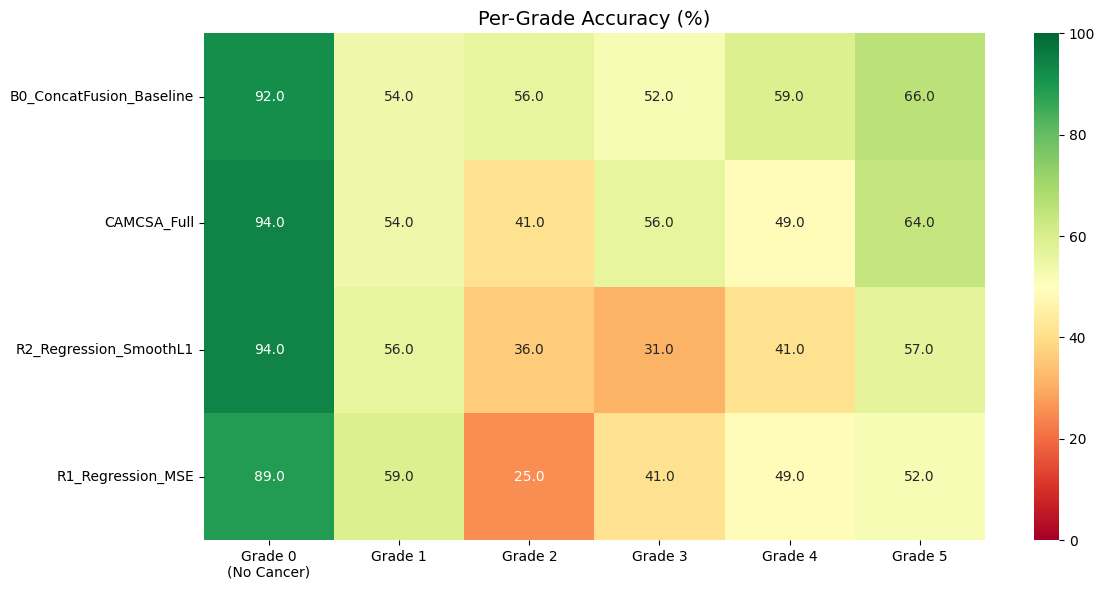

In [20]:
# 1. Per-Grade Accuracy Heatmap
fig, ax = plt.subplots(figsize=(12, 6))

models = []
data = []
for name, r in sorted_results:
    models.append(name)
    row = [get_pga(r, g) * 100 for g in range(6)]
    data.append(row)

data = np.array(data)

sns.heatmap(data, annot=True, fmt='.1f', cmap='RdYlGn',
            xticklabels=['Grade 0\n(No Cancer)', 'Grade 1', 'Grade 2', 'Grade 3', 'Grade 4', 'Grade 5'],
            yticklabels=models, ax=ax, vmin=0, vmax=100)
ax.set_title('Per-Grade Accuracy (%)', fontsize=14)

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['results_dir'], 'per_grade_accuracy.png'), dpi=300, bbox_inches='tight')
plt.show()

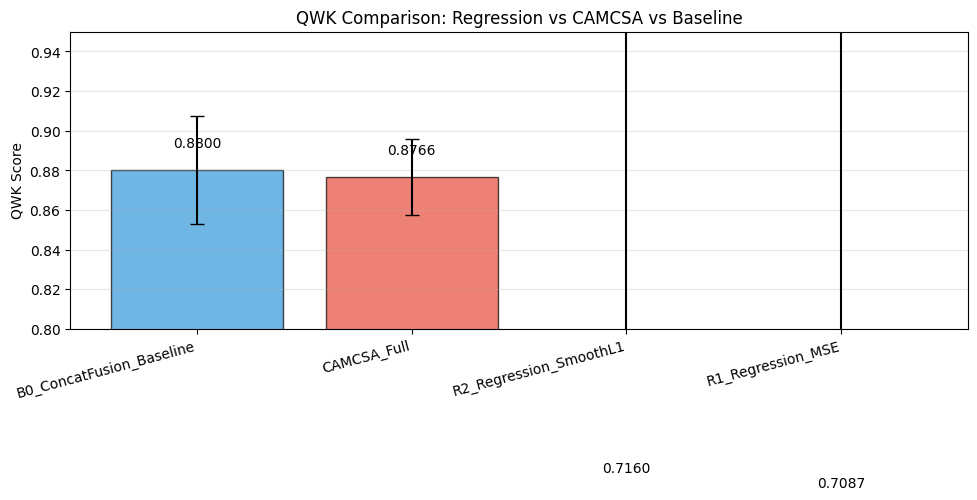

In [21]:
# 2. QWK Comparison Bar Chart
fig, ax = plt.subplots(figsize=(10, 6))

names = [name for name, _ in sorted_results]
means = [r['qwk']['mean'] for _, r in sorted_results]
stds = [r['qwk']['std'] for _, r in sorted_results]

colors = ['#3498db', '#e74c3c', '#f39c12', '#2ecc71']
bars = ax.bar(range(len(names)), means, yerr=stds, capsize=5, color=colors[:len(names)], alpha=0.7, edgecolor='black')

ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=15, ha='right')
ax.set_ylabel('QWK Score')
ax.set_title('QWK Comparison: Regression vs CAMCSA vs Baseline')
ax.set_ylim(0.8, 0.95)
ax.grid(axis='y', alpha=0.3)

for bar, val in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{val:.4f}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['results_dir'], 'qwk_comparison.png'), dpi=300, bbox_inches='tight')
plt.show()

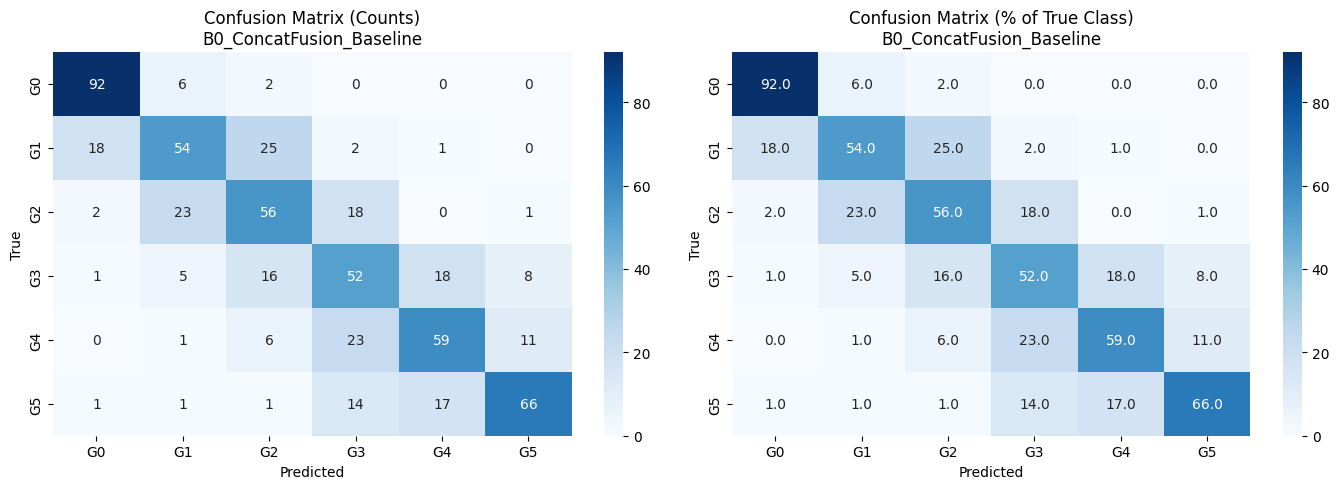

In [22]:
# 3. Confusion Matrix for Best Model
best_name, best_result = sorted_results[0]
cm = np.array(best_result['confusion_matrix'])
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['G0', 'G1', 'G2', 'G3', 'G4', 'G5'],
            yticklabels=['G0', 'G1', 'G2', 'G3', 'G4', 'G5'])
axes[0].set_title(f'Confusion Matrix (Counts)\n{best_name}')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

sns.heatmap(cm_normalized, annot=True, fmt='.1f', cmap='Blues', ax=axes[1],
            xticklabels=['G0', 'G1', 'G2', 'G3', 'G4', 'G5'],
            yticklabels=['G0', 'G1', 'G2', 'G3', 'G4', 'G5'])
axes[1].set_title(f'Confusion Matrix (% of True Class)\n{best_name}')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')

plt.tight_layout()
plt.savefig(os.path.join(CONFIG['results_dir'], 'confusion_matrix_best.png'), dpi=300, bbox_inches='tight')
plt.show()

## FINAL SUMMARY

In [23]:
overall_best = sorted_results[0]
baseline = all_results.get('B0_ConcatFusion_Baseline', {})

print('\n' + '='*100)
print('FINAL SUMMARY')
print('='*100)

print(f'''
BEST MODEL: {overall_best[0]}
  Description: {overall_best[1]["description"]}

  METRICS:
    QWK:              {overall_best[1]["qwk"]["mean"]:.4f} +/- {overall_best[1]["qwk"]["std"]:.4f}
    Grading Accuracy: {overall_best[1]["grading_accuracy"]["mean"]*100:.2f}%
    Binary Accuracy:  {overall_best[1]["binary_accuracy"]["mean"]*100:.2f}%
    Macro F1:         {overall_best[1]["macro_f1"]["mean"]:.4f}

  PER-GRADE ACCURACY:
    Grade 0: {get_pga(overall_best[1], 0)*100:.1f}%
    Grade 1: {get_pga(overall_best[1], 1)*100:.1f}%
    Grade 2: {get_pga(overall_best[1], 2)*100:.1f}%
    Grade 3: {get_pga(overall_best[1], 3)*100:.1f}%
    Grade 4: {get_pga(overall_best[1], 4)*100:.1f}%
    Grade 5: {get_pga(overall_best[1], 5)*100:.1f}%

COMPARISON VS BASELINE:
  Baseline QWK: {baseline.get("qwk", {}).get("mean", 0):.4f}
  Best QWK:     {overall_best[1]["qwk"]["mean"]:.4f}
  Improvement:  {overall_best[1]["qwk"]["mean"] - baseline.get("qwk", {}).get("mean", 0):+.4f}
''')

# Save final summary
with open(os.path.join(CONFIG['results_dir'], 'final_summary.json'), 'w') as f:
    json.dump({
        'best_model': overall_best[0],
        'best_qwk': overall_best[1]['qwk']['mean'],
        'baseline_qwk': baseline.get('qwk', {}).get('mean', 0),
        'improvement': overall_best[1]['qwk']['mean'] - baseline.get('qwk', {}).get('mean', 0),
        'all_results': {k: {'qwk': v['qwk']['mean'], 'std': v['qwk']['std']} for k, v in all_results.items()}
    }, f, indent=2)

print('='*100)
print(f'Results saved to: {CONFIG["results_dir"]}')
print('\nDONE!')


FINAL SUMMARY

BEST MODEL: B0_ConcatFusion_Baseline
  Description: ConcatFusion Baseline (Current Best: 0.8832)
  
  METRICS:
    QWK:              0.8800 +/- 0.0272
    Grading Accuracy: 63.17%
    Binary Accuracy:  95.00%
    Macro F1:         0.6265
  
  PER-GRADE ACCURACY:
    Grade 0: 92.0%
    Grade 1: 54.0%
    Grade 2: 56.0%
    Grade 3: 52.0%
    Grade 4: 59.0%
    Grade 5: 66.0%

COMPARISON VS BASELINE:
  Baseline QWK: 0.8800
  Best QWK:     0.8800
  Improvement:  +0.0000

Results saved to: /content/drive/MyDrive/CLAM_TR_Results/v14_Regression_CAMCSA/

DONE!
